# ЛР 1. Начало работы с ML-проектом: формализация задачи и первичный анализ данных

**Датасет:** Dota 2 — классификация локации энергии Древних  
**Подгруппа:** МО-241  

## Содержание

1. [Постановка задачи и предметная область](#sec1)
2. [Описание признаков](#sec2)
3. [Фиксация виртуального окружения](#sec3)
4. [Загрузка данных и первичный осмотр](#sec4)
5. [Анализ природы признаков](#sec5)
6. [Диагностика пропусков](#sec6)
7. [Методы заполнения пропусков](#sec7)
8. [Корреляции и распределения по классам](#sec8)
9. [Приведение типов](#sec10)
10. [Разделение на train/test и применение заполнения](#sec10)
11. [Выводы по работе](#sec11)

<a id='sec1'></a>
## 1. Постановка задачи и предметная область

### Бизнес-контекст

По легенде заказчика (Invoker), в мир проникают микроскопические осколки двух враждующих сил — Radiant и Dire. Эти осколки меняют свойства материи, концентрируясь в различных слоях вещества: внешних, внутренних, промежуточных барьерах. Цель — научиться определять **где именно** сосредоточилась чужеродная энергия ещё до того, как её влияние станет заметным невооружённым глазом.

### Формализация ML-задачи

| Параметр | Значение |
|----------|----------|
| **Тип задачи** | Многоклассовая классификация (multiclass classification) |
| **Объект** | Образец вещества с обнаруженными признаками проникновения энергии |
| **Целевой признак** | `class` — локация концентрации осколков (8 категорий) |
| **Входные признаки** | 7 характеристик отклика на энергию Radiant/Dire, наличие меток, заряд эссенции, состав внутренней энергии, характер распространения |
| **Выход модели** | Предсказание локации концентрации (`inner_core`, `outer_layer`, `deep_barrier`, и др.) для нового образца |

### Особенности данных

- Малый объём выборки: **n = 336 наблюдений**.
- Сильная несбалансированность классов: доминирует `inner_core` (42.56%), три класса имеют ≤ 5 наблюдений (статистически ненадёжны).
- Присутствуют пропуски в 4 из 7 признаков (максимум 26.19%).
- Два признака имеют индикаторную природу (бинарные события), а не непрерывную.

<a id='sec2'></a>
## 2. Описание признаков

| Признак | Семантика | Тип данных |
|---------|------------------------|------------|
| `radiant_resonance` | Отклик вещества на энергию Radiant | float64 |
| `dire_resonance` | Отклик на энергию Dire | float64 |
| `arcane_mark` | Наличие особой магической метки | float64 |
| `energy_charge` | Заряд эссенции | float64 |
| `essence_composition` | Состав внутренней энергии | float64
| `outer_energy_flow` | Характер распространения по внешним слоям | float64 |
| `inner_energy_flow` | Характер распространения по внутренним слоям | float64 |
| `class` | Локация концентрации осколков | str |

### Классы целевого признака (по убыванию частоты)

| Класс | Доля | Кол-во | Надёжность статистики |
|-------|------|--------|----------------------|
| `inner_core` | 42.56% | 143 | Высокая |
| `inner_barrier` | 22.92% | 77 | Высокая |
| `inner_layer` | 15.48% | 52 | Средняя |
| `deep_barrier` | 10.42% | 35 | Средняя |
| `outer_layer` | 5.95% | 20 | Низкая |
| `outer_crust` | 1.49% | 5 | Очень низкая (n<10) |
| `penetration_layer` | 0.60% | 2 | Статистически ненадёжен |
| `inner_crust` | 0.60% | 2 | Статистически ненадёжен |

**Вывод.** Три последних класса дают суммарно 9 наблюдений (2.7%)

<a id='sec3'></a>
## 3. Фиксация виртуального окружения

Для воспроизводимости работы фиксируем версии ключевых библиотек и глобальный seed.

| Библиотека | Версия | Назначение |
|------------|--------|------------|
| Python | 3.13+ | Интерпретатор |
| pandas | ≥2.0 | Работа с таблицами |
| numpy | ≥1.24 | Численные вычисления |
| scikit-learn | ≥1.3 | Моделирование, импутация, сплит |
| matplotlib | ≥3.7 | Визуализация |
| seaborn | ≥0.12 | Статистическая визуализация |
| missingno | ≥0.5 | Диагностика пропусков |

**Глобальный seed:** `SEED = 5`. Используется во всех операциях случайности: `train_test_split`, генерация масок для оценки imputer'ов, инициализация моделей.

**Принцип фиксации:** все ячейки ноутбука идемпотентны при повторном запуске после `Restart Kernel and Run All Cells`. Изменения рабочего `df` происходят только в явно обозначенных блоках-мутаторах (блоки 9 и 10).

In [352]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
import warnings

In [353]:
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
SEED = 5
np.random.seed(SEED)

<a id='sec4'></a>
## 4. Загрузка данных и первичный осмотр

In [354]:
PATH = 'dota.csv'
df = pd.read_csv(PATH, sep=';', decimal='.')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 50)

In [355]:
df.head(10)

,radiant_resonance,dire_resonance,arcane_mark,energy_charge,essence_composition,outer_energy_flow,inner_energy_flow,class
0,0.49,0.29,NaN,0.5,0.56,0.24,0.35,inner_core
1,0.07,0.40,0.48,0.5,0.54,0.35,0.44,inner_core
2,0.56,0.40,0.48,0.5,0.49,0.37,0.46,inner_core
3,0.59,0.49,0.48,0.5,0.52,0.45,0.36,inner_core
4,NaN,NaN,0.48,0.5,0.55,0.25,0.35,inner_core
5,0.67,NaN,0.48,0.5,0.36,0.38,0.46,inner_core
6,0.29,0.28,0.48,0.5,0.44,0.23,0.34,inner_core
7,NaN,0.34,0.48,0.5,0.51,0.28,0.39,inner_core
8,0.20,0.44,0.48,0.5,0.46,0.51,0.57,inner_core
9,0.42,0.40,0.48,0.5,0.56,0.18,0.30,inner_core


In [356]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float64
 1   dire_resonance       289 non-null    float64
 2   arcane_mark          312 non-null    float64
 3   energy_charge        316 non-null    float64
 4   essence_composition  336 non-null    float64
 5   outer_energy_flow    336 non-null    float64
 6   inner_energy_flow    336 non-null    float64
 7   class                336 non-null    str    
dtypes: float64(7), str(1)
memory usage: 21.1 KB


In [357]:
missing = pd.DataFrame({
    'count': df.isna().sum(),
    'percent': (df.isna().mean() * 100).round(2)
})
missing[missing['count'] > 0]

,count,percent
radiant_resonance,88,26.19
dire_resonance,47,13.99
arcane_mark,24,7.14
energy_charge,20,5.95


In [358]:
df['class'].value_counts(dropna=False)

class
inner_core           143
inner_barrier         77
inner_layer           52
deep_barrier          35
outer_layer           20
outer_crust            5
penetration_layer      2
inner_crust            2
Name: count, dtype: int64

In [359]:
(df['class'].value_counts(dropna=False, normalize=True) * 100).round(2)

class
inner_core           42.56
inner_barrier        22.92
inner_layer          15.48
deep_barrier         10.42
outer_layer           5.95
outer_crust           1.49
penetration_layer     0.60
inner_crust           0.60
Name: proportion, dtype: float64

In [360]:
df.duplicated().sum()

np.int64(0)

Дубликатов нет

### 4.1. Выводы по первичному осмотру

**Наблюдения.**
- Выборка: **336 наблюдений, 8 столбцов** (7 признаков + целевой `class`).
- Полных дубликатов нет — повторных образцов в данных нет.
- Пропуски сосредоточены в 4 признаках: `radiant_resonance` (26.19%),
  `dire_resonance` (13.99%), `arcane_mark` (7.14%), `energy_charge` (5.95%).
  В `essence_composition`, `outer_energy_flow`, `inner_energy_flow` и `class`
  пропусков нет.
- Целевой признак **сильно несбалансирован**: доминирует `inner_core` (42.56%),
  далее `inner_barrier` (22.92%), `inner_layer` (15.48%), `deep_barrier` (10.42%),
  `outer_layer` (5.95%); классы `outer_crust` (1.49%), `penetration_layer` и
  `inner_crust` (по 0.60%, = 2 наблюдения) статистически ненадёжны.

**Вывод.** Данные читаются корректно, дубликатов нет, целевая переменная заполнена
полностью. Главные особенности этапа — высокая доля пропусков в двух резонансных
признаках и экстремальная несбалансированность классов с несколькими
сверхредкими категориями. Оба факта нужно учитывать при подготовке и валидации.

In [361]:
df.describe()

,radiant_resonance,dire_resonance,arcane_mark,energy_charge,essence_composition,outer_energy_flow,inner_energy_flow
count,248.000000,289.000000,312.000000,316.000000,336.000000,336.000000,336.000000
mean,0.496653,0.503356,0.495000,0.501582,0.500030,0.500179,0.499732
std,0.197161,0.153454,0.087174,0.028127,0.122376,0.215751,0.209411
min,0.000000,0.160000,0.480000,0.500000,0.000000,0.030000,0.000000
25%,0.340000,0.400000,0.480000,0.500000,0.420000,0.330000,0.350000
50%,0.500000,0.470000,0.480000,0.500000,0.495000,0.455000,0.430000
75%,0.662500,0.570000,0.480000,0.500000,0.570000,0.710000,0.710000
max,0.890000,1.000000,1.000000,1.000000,0.880000,1.000000,0.990000


In [362]:
pd.concat(
    {c: df[c].value_counts(dropna=False) for c in ['arcane_mark', 'energy_charge']},
    axis=1
)

,arcane_mark,energy_charge
0.48,303.0,NaN
NaN,24.0,20.0
1.00,9.0,1.0
0.50,NaN,315.0


### 5.1. Вывод о природе признаков

По кардинальности и доле моды признаки распадаются на две группы:

- **Непрерывные** (`radiant_resonance`, `dire_resonance`, `essence_composition`,
  `outer_energy_flow`, `inner_energy_flow`): 59–82 уникальных значения, мода не
  доминирует — трактуются как вещественные величины.
- **Дискретные-индикаторные** (`arcane_mark`, `energy_charge`): ровно 2 реальных
  уровня плюс пропуск. `arcane_mark` — бинарный флаг события (базовое `0.48` против
  редкого `1.00`); `energy_charge` — почти константа (`0.50` на 93.75%, уровень `1.00`
  представлен одним наблюдением). Подавать их в модель как `float` некорректно:
  непрерывной градации в них нет, есть только факт отклонения от базового уровня.

Это согласуется с семантикой задачи: оба признака описывают *наличие* метки / заряда,
а не измеренную силу.

<a id='sec6'></a>
## 6. Диагностика пропусков

**Обоснование.** Долей пропусков по каждому столбцу картина не исчерпывается: важно, концентрируются ли потери в одних и тех же строках (тогда оправдано удаление наблюдений) или размазаны по выборке (тогда удалять нельзя — теряем целую информацию). Matrix plot дополняет числа визуальной оценкой блочности.

In [363]:
miss_cols = ['radiant_resonance', 'dire_resonance', 'arcane_mark', 'energy_charge']

row_miss_count = df[miss_cols].isna().sum(axis=1)
pd.crosstab(row_miss_count, df['class'], margins=True)

class,deep_barrier,inner_barrier,inner_core,inner_crust,inner_layer,outer_crust,outer_layer,penetration_layer,All
row_0,,,,,,,,,
0,22,39,82,2,27,3,12,1,188
1,10,32,50,0,19,1,7,1,120
2,2,6,10,0,5,1,1,0,25
3,1,0,1,0,1,0,0,0,3
All,35,77,143,2,52,5,20,2,336


In [364]:
df[miss_cols].isna().astype(int).corr().round(3)

,radiant_resonance,dire_resonance,arcane_mark,energy_charge
radiant_resonance,1.000,0.053,-0.034,-0.035
dire_resonance,0.053,1.000,0.021,-0.065
arcane_mark,-0.034,0.021,1.000,0.174
energy_charge,-0.035,-0.065,0.174,1.000


<Axes: >

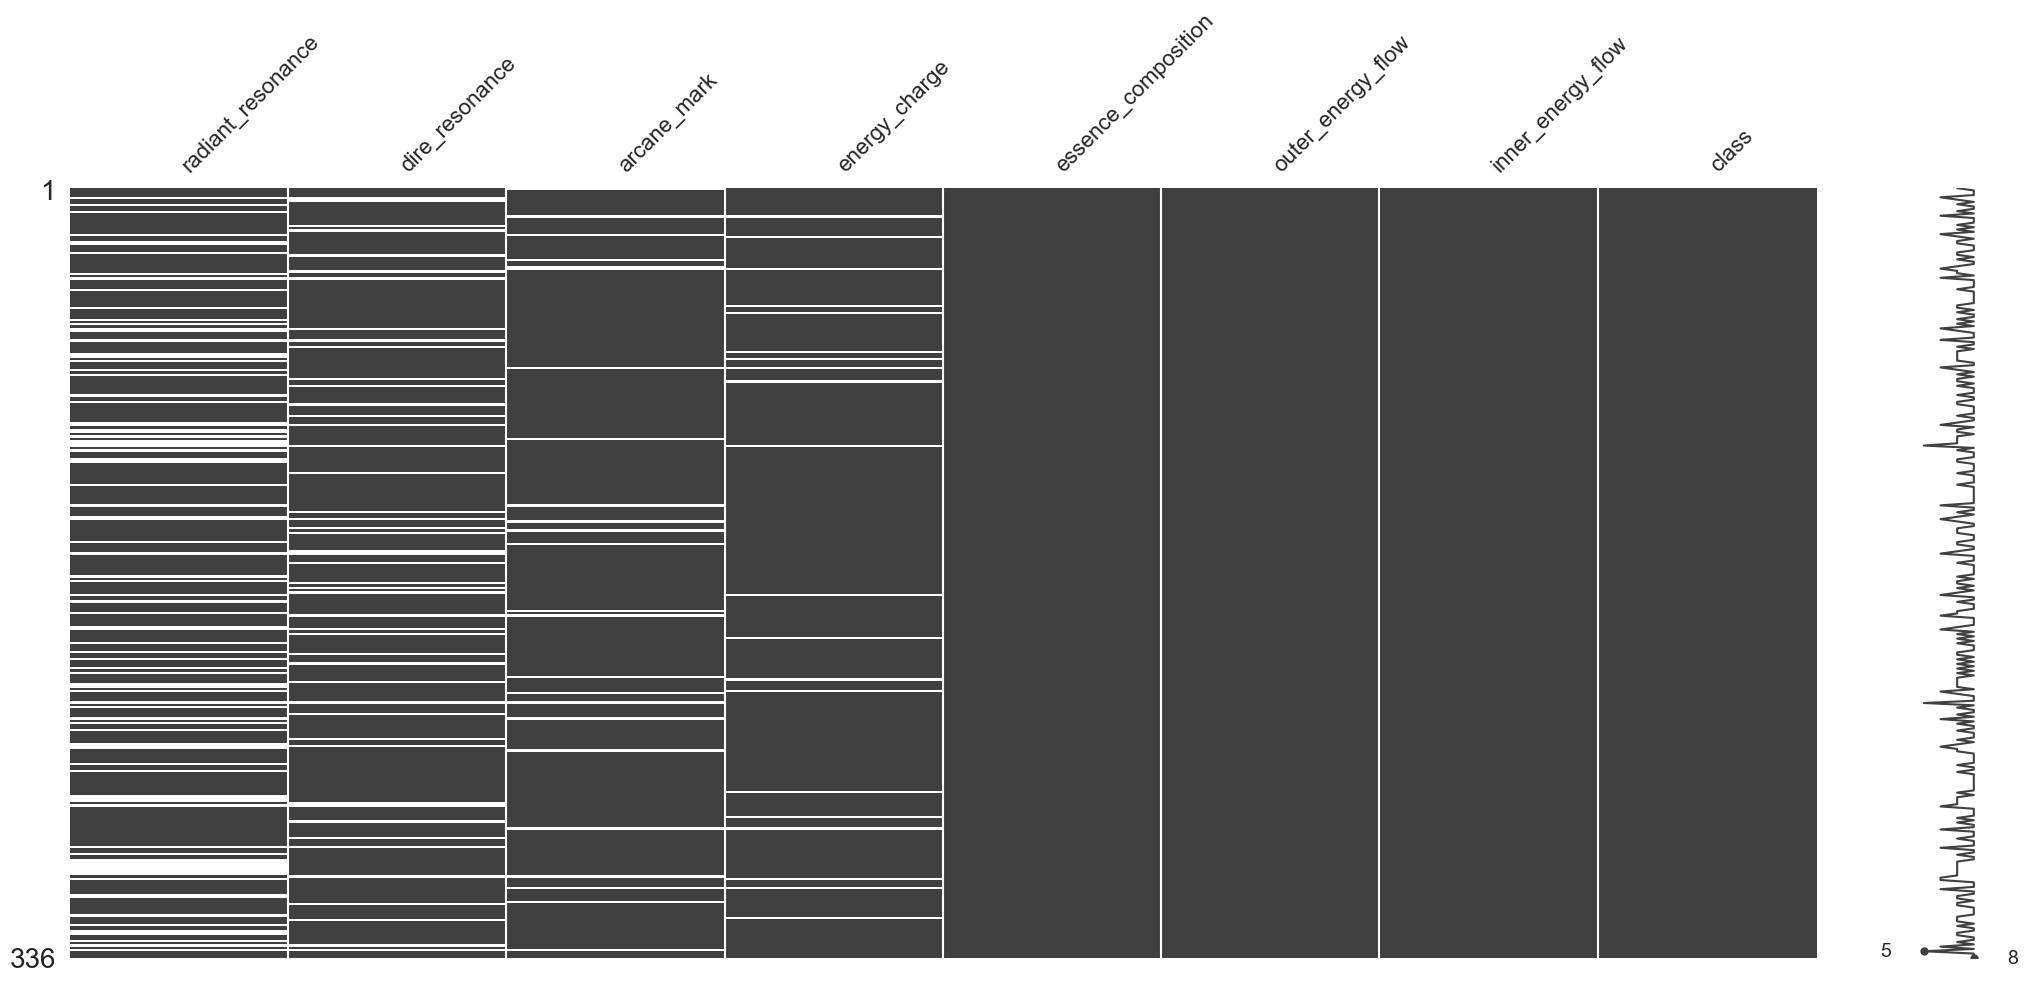

In [365]:
msno.matrix(df)

### 6.1. Выводы по структуре пропусков

**Наблюдения.**
- По числу пропусков на строку: подавляющее большинство наблюдений имеют 0 или 1
  пропуск; лишь единичные строки теряют сразу несколько значений.
- Корреляции индикаторов пропуска слабые, кроме заметной связи между
  `arcane_mark` и `energy_charge` — согласуется с их общей природой редких событий.
- Matrix plot: столбцы без пропусков идут сплошным фоном, плотность светлых полос
  убывает в порядке `radiant_resonance > dire_resonance > arcane_mark >
  energy_charge`, длинных горизонтальных «разрезов» через несколько столбцов нет.

**Вывод.** Потери носят **диффузный, а не блочный** характер. Удаление строк по
числу пропусков неоправданно: мы потеряли бы наблюдения с целым остальным
содержанием. Фокус смещается на точечное заполнение и, при подтверждённой связи с
target, на индикаторы пропуска. Ограничение matrix plot: он не отражает связь
пропусков с классом — этот вопрос закрывается отдельным кросс-табом.

In [366]:
tab = (df[miss_cols].isna().groupby(df['class']).mean() * 100).round(2)
tab.loc['ALL'] = (df[miss_cols].isna().mean() * 100).round(2)
tab

,radiant_resonance,dire_resonance,arcane_mark,energy_charge
class,,,,
deep_barrier,28.57,11.43,8.57,0.00
inner_barrier,24.68,19.48,7.79,5.19
inner_core,25.17,12.59,6.29,6.99
inner_crust,0.00,0.00,0.00,0.00
inner_layer,36.54,11.54,7.69,5.77
outer_crust,0.00,20.00,20.00,20.00
outer_layer,20.00,15.00,0.00,10.00
penetration_layer,0.00,0.00,50.00,0.00
ALL,26.19,13.99,7.14,5.95


### 6.2. Связь пропусков с целевым классом (MCAR/MAR)

**Наблюдения.** Сравниваем доли пропусков внутри каждого класса с общей долей
(`ALL`: `radiant_resonance` 26.19%, `dire_resonance` 13.99%, `arcane_mark` 7.14%,
`energy_charge` 5.95%).

- В **надёжных** классах (`inner_core` n=143, `inner_barrier` n=77, `inner_layer`
  n=52, `deep_barrier` n=35) отклонения умеренные: максимум — `radiant_resonance`
  в `inner_layer` (36.5% против 26.2%, ≈ +10 п.п.) и `dire_resonance` в
  `inner_barrier` (19.5% против 14.0%, ≈ +5.5 п.п.). При указанных объёмах
  стандартная ошибка доли составляет ≈ 5–6 п.п., поэтому оба отклонения лежат в
  пределах ≈ 1–2 стандартных ошибок и статистически незначимы.
- Экстремальные значения (`outer_crust`, `penetration_layer`, `inner_crust`:
  доли 0% или 20–50%) приходятся на классы с n = 2–5, где одно наблюдение меняет
  долю на 20–50 п.п. — это шум разметки редких классов, а не структура потерь.

**Вывод.** Систематической зависимости «пропуск ⇒ конкретный класс» в надёжных
классах не обнаружено: картина близка к **MCAR**. Следовательно, индикаторы
пропуска (`is_missing`) **не вводятся как обязательные признаки** — сам факт
потери не несёт сигнала о локации энергии. Пропуск в `arcane_mark` по‑прежнему
трактуется семантически (база `0.48` = «метки нет»), а не статистикой.

<a id='sec7'></a>
## 7. Методы заполнения пропусков

Предлогаются два метода: **статистический** (подбор константы mean/median/mode с проверкой через KL-дивергенцию) и **машинный** (KNNImputer / MICE). Оба исследуются ниже

### 7.1. Статистический подбор значения заполнения (KL-дивергенция)

**Обоснование.** Лекция предупреждает: заполнение константой может исказить распределение признака. Поэтому для `radiant_resonance` и `dire_resonance` перебираем кандидатов (mean / median / mode), строим гистограммы «до» и «после» на общих бинах и считаем KL-дивергенцию между исходным и заполненным распределением. Чем ближе дивергенция к нулю и чем меньше меняется форма гистограммы, тем менее разрушительно заполнение.

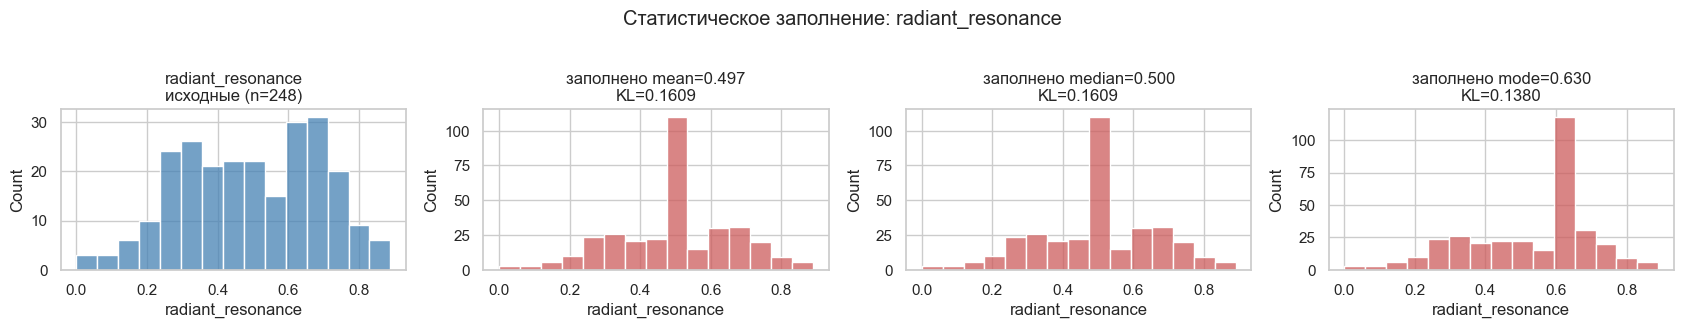

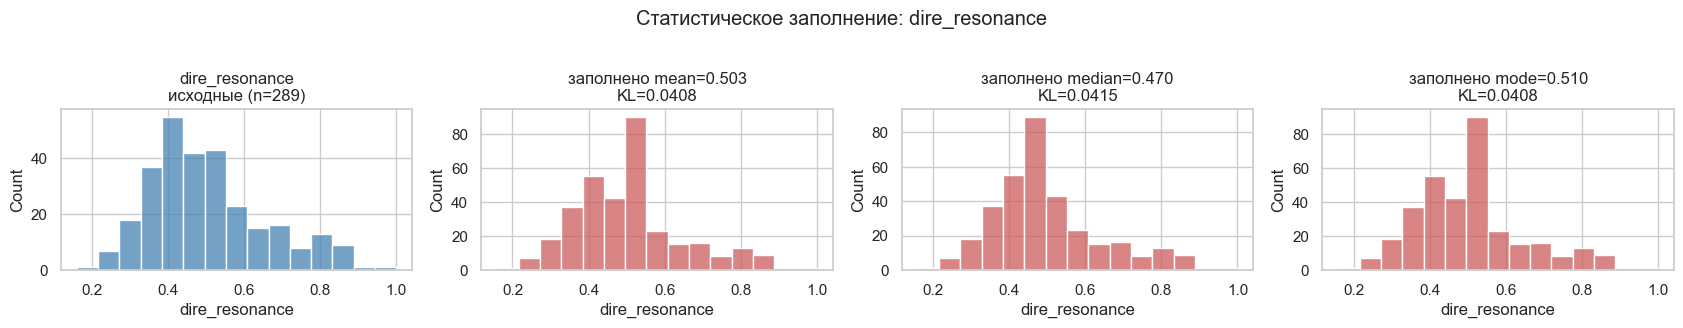

,mean,median,mode
radiant_resonance,0.1609,0.1609,0.1380
dire_resonance,0.0408,0.0415,0.0408


In [367]:
def kl_hist(p_vals, q_vals, bins=15):
    lo, hi = p_vals.min(), p_vals.max()
    edges = np.linspace(lo, hi, bins + 1)
    cp, _ = np.histogram(p_vals, bins=edges)
    cq, _ = np.histogram(q_vals, bins=edges)
    p = cp / cp.sum() + 1e-9
    q = cq / cq.sum() + 1e-9
    p /= p.sum()
    q /= q.sum()
    return float(np.sum(p * np.log(p / q)))


def plot_fill_compare(col, bins=15):
    s = df[col]
    x = s.dropna()
    lo, hi = x.min(), x.max()
    edges = np.linspace(lo, hi, bins + 1)

    cands = {
        'mean': s.mean(),
        'median': s.median(),
        'mode': s.mode().iloc[0],
    }

    fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
    sns.histplot(x, bins=edges, ax=axes[0], color='steelblue')
    axes[0].set_title(f'{col}\nисходные (n={len(x)})')

    kl_rows = {}
    for ax, (name, val) in zip(axes[1:], cands.items()):
        filled = s.fillna(val)
        kl = kl_hist(x, filled)
        kl_rows[name] = round(kl, 4)
        sns.histplot(filled, bins=edges, ax=ax, color='indianred')
        ax.set_title(f'заполнено {name}={val:.3f}\nKL={kl:.4f}')

    fig.suptitle(f'Статистическое заполнение: {col}', y=1.02)
    plt.tight_layout()
    plt.show()
    return kl_rows


kl_table = {}
for col in ['radiant_resonance', 'dire_resonance']:
    kl_table[col] = plot_fill_compare(col)

pd.DataFrame(kl_table).T

### 7.1.1. Выводы по статистическому заполнению

**`radiant_resonance` — мода выигрывает у среднего/медианы.**
- Исходное распределение **двумодальное**: горбы около `0.25–0.30` и `0.60–0.75`, между ними провал плотности в районе `0.45–0.50`.
- `mean`/`median` (`≈0.50`) попадают ровно в провал → возникает **чужеродный острый шип в пустой зоне**.
- `mode` (`0.63`) попадает во второй, уже населённый горб → шип сливается с существующим пиком, **двумодальная форма сохраняется**.
- KL(mode)=0.138 < KL(mean)=KL(median)=0.161.

**`dire_resonance` — заполнение почти не искажает распределение.**
- Все KL на порядок меньше, чем у `radiant_resonance` (`≈0.04` против `≈0.14–0.16`).
- Распределение правосторонне скошенное, пик около `0.40–0.45`, длинный хвост до `1.0`.
- Tie-break: предпочитаем значение, реально присутствующее в признаке (мода `0.51`), а не синтетическое среднее.

**Единый принцип выбора.** Минимизируем KL → при равенстве выбираем кандидата, чьё значение реально встречается в признаке → визуально проверяем отсутствие шипа в провале плотности.

### 7.2. Машинный метод заполнения и честная схема сравнения

**Обоснование.** Статистический baseline подставляет одно число и использует только сам признак. Машинные методы восстанавливают каждое пропущенное значение по **всем остальным признакам** объекта. Чтобы решить, стоит ли усложнять пайплайн, нужно измерить это преимущество численно.

**Методология оценки:**
1. Берём **полигон** — строки, во всех 5 непрерывных признаках которых нет пропусков.
2. В одном полном столбце полигона случайно маскируем `frac` значений (имитируем реальный уровень потерь: 0.14 и 0.26).
3. Восстанавливаем замаскированные позиции двумя семействами: статистика (mean/median/mode по непровпущенной части) и машина (KNNImputer / IterativeImputer по всей матрице признаков).
4. Меряем MAE и RMSE только по замаскированным позициям против оригинала.
5. Повторяем на нескольких seeds и усредняем.

In [368]:
try:
    from sklearn.impute import IterativeImputer
except ImportError:
    from sklearn.experimental import enable_iterative_imputer
    from sklearn.impute import IterativeImputer

num_cols = [
    'radiant_resonance', 'dire_resonance', 'essence_composition',
    'outer_energy_flow', 'inner_energy_flow',
]

df_comp = df[df[num_cols].notna().all(axis=1)].reset_index(drop=True)
print('размер полигона:', df_comp.shape)

размер полигона: (216, 8)


In [369]:
def error_one_method(method, orig, mask_idx, X_full, col_idx, stat_val=None):
    if method in ('mean', 'median', 'mode'):
        filled = orig.copy()
        filled[mask_idx] = stat_val
        pred = filled[mask_idx]
    else:
        X = X_full.copy()
        X[mask_idx, col_idx] = np.nan
        imp = KNNImputer() if method == 'knn' else IterativeImputer(random_state=0, max_iter=15)
        Xt = imp.fit_transform(X)
        pred = Xt[mask_idx, col_idx]

    err = pred - orig[mask_idx]
    mae = np.abs(err).mean()
    rmse = np.sqrt((err ** 2).mean())
    return mae, rmse

In [370]:
def eval_pair(df_comp, col, frac, methods=('mean','median','mode','knn','mice'), n_seeds=20):
    orig = df_comp[col].to_numpy(dtype=float)
    n = len(orig); k = int(round(frac * n)); col_idx = num_cols.index(col)
    X_full = df_comp[num_cols].to_numpy(dtype=float)

    acc = {m: {'mae': [], 'rmse': []} for m in methods}
    for seed in range(n_seeds):
        rng = np.random.default_rng(seed)
        mask_idx = rng.choice(n, size=k, replace=False)
        s = orig.copy(); s[mask_idx] = np.nan
        ps = pd.Series(s)
        stat_vals = {'mean': ps.mean(), 'median': ps.median(), 'mode': ps.mode().iloc[0]}
        for m in methods:
            mae, rmse = error_one_method(m, orig, mask_idx, X_full, col_idx, stat_vals.get(m))
            acc[m]['mae'].append(mae); acc[m]['rmse'].append(rmse)

    out = []
    for m in methods:
        out.append({'polygon_col': col, 'mask_frac': frac, 'method': m,
                    'MAE_mean': np.mean(acc[m]['mae']), 'MAE_std': np.std(acc[m]['mae']),
                    'RMSE_mean': np.mean(acc[m]['rmse']), 'RMSE_std': np.std(acc[m]['rmse'])})
    return pd.DataFrame(out)

In [371]:
result = pd.concat(
    [eval_pair(df_comp, c, f)
     for c in ['essence_composition', 'outer_energy_flow']
     for f in [0.14, 0.26]],
    ignore_index=True
)
result.round(4)

,polygon_col,mask_frac,method,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,essence_composition,0.14,mean,0.0992,0.0140,0.1265,0.0177
1,essence_composition,0.14,median,0.0994,0.0139,0.1265,0.0175
2,essence_composition,0.14,mode,0.1158,0.0213,0.1455,0.0250
3,essence_composition,0.14,knn,0.0944,0.0156,0.1268,0.0184
4,essence_composition,0.14,mice,0.0925,0.0137,0.1224,0.0184
5,essence_composition,0.26,mean,0.0916,0.0127,0.1172,0.0158
6,essence_composition,0.26,median,0.0919,0.0127,0.1172,0.0158
7,essence_composition,0.26,mode,0.1056,0.0155,0.1325,0.0189
8,essence_composition,0.26,knn,0.0910,0.0130,0.1209,0.0157
9,essence_composition,0.26,mice,0.0852,0.0127,0.1129,0.0171


### 7.2.1. Выводы по машинному заполнению

**Блок `essence_composition` (оба уровня потерь).** Машина **не выигрывает**:
все методы в пределах std (~0.013–0.015), статистически неразличимы.
Вывод: для этого признака межпризнакового сигнала мало.

**Блок `outer_energy_flow` (оба уровня потерь).** Картина противоположная:
`knn` лучше лучшей статистики примерно **в 3 раза**, и std у knn маленький — эффект устойчивый.
Вывод: сильные межпризнаковые связи позволяют машине восстановить пропуск по соседям.

**Сводный вывод (асимметрия риска).** `knn` нигде не проигрывает значимо лучшей статистике, но в одном столбце выигрывает в разы. Риск выбрать knn всегда мал, потенциал выигрыша велик.

**Связь с корреляциями.** Корреляционная матрица объясняет результат: у `outer` есть мощный предиктор-сосед `inner` (r=0.81), по которому машина восстанавливает пропуск; у `essence` сильных соседей нет (max r=0.28), поэтому машине не на что опереться.

**Решение.** Для непрерывных резонансов (`radiant_resonance`, `dire_resonance`) берём `knn` как основной метод заполнения. Статистический baseline (`mode`) остаётся как эталон сравнения. `arcane_mark` — вне обеих веток: интерпретационное заполнение `0.48`.

In [372]:
fillna_method = {
    'radiant_resonance': 'knn',
    'dire_resonance':    'knn',
    'arcane_mark':       'interpretation',
}

machine_params = {'knn': {'n_neighbors': 5}}

baseline_mode = {
    'radiant_resonance': df['radiant_resonance'].mode().iloc[0],
    'dire_resonance':    df['dire_resonance'].mode().iloc[0],
}
fillna_interpretation = {'arcane_mark': 0.48}

fillna_method, machine_params, baseline_mode, fillna_interpretation

({'radiant_resonance': 'knn',
  'dire_resonance': 'knn',
  'arcane_mark': 'interpretation'},
 {'knn': {'n_neighbors': 5}},
 {'radiant_resonance': np.float64(0.63), 'dire_resonance': np.float64(0.51)},
 {'arcane_mark': 0.48})

<a id='sec8'></a>
## 8. Корреляции и распределения по классам

### 8.1. Корреляции непрерывных признаков

**Обоснование.** Нужно понять: (а) нет ли сильных линейных связей / дублей; (б) какие признаки связаны между собой, что объясняет, почему машинный заполнитель смог вытащить сигнал из соседей.

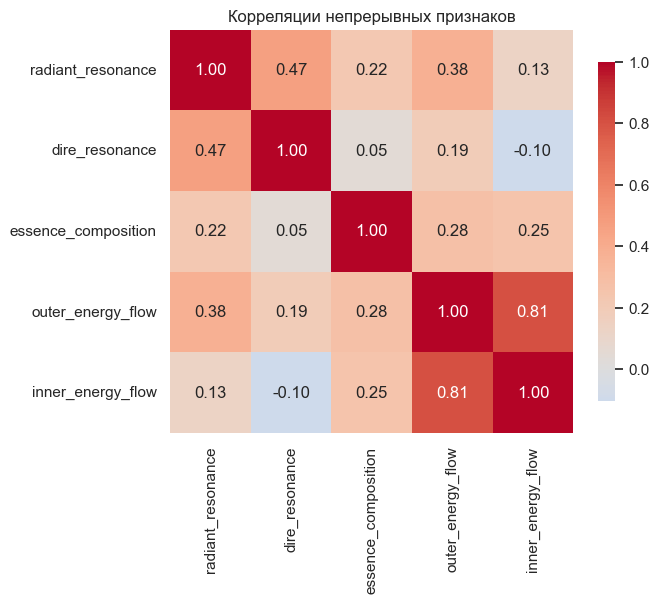

,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow
radiant_resonance,1.000,0.469,0.223,0.381,0.129
dire_resonance,0.469,1.000,0.046,0.193,-0.103
essence_composition,0.223,0.046,1.000,0.279,0.253
outer_energy_flow,0.381,0.193,0.279,1.000,0.809
inner_energy_flow,0.129,-0.103,0.253,0.809,1.000


In [373]:
corr = df[num_cols].corr().round(3)

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Корреляции непрерывных признаков')
plt.show()

corr

### 8.1.1. Выводы по корреляционной матрице

- **Сильная связь `outer_energy_flow ↔ inner_energy_flow` (r = 0.81).** Два признака частично дублируют друг друга, но у `inner` остаётся ≈ 34% уникальной дисперсии.
- **Умеренная связь `radiant_resonance ↔ dire_resonance` (r = 0.47).** Оба отклика частично отражают общий уровень проникновения, но 0.47 — не дубль.
- **`essence_composition` — наиболее изолированный признак** (максимальная связь 0.28). Несёт уникальный сигнал.
- Автоматических дублей (|r| ≥ 0.9) нет; кандидат на рассмотрение — только пара `outer`/`inner`.

**Связь с результатом машинного заполнения (7.2).** У `outer` есть сильный предиктор-сосед `inner` (r=0.81), по которому машина восстанавливает пропуск; у `essence` сильных соседей нет (max 0.28), поэтому скатывается к константе. Корреляционная матрица независимо подтверждает эмпирический результат полигона.

**Решение по дублям.** Пару `outer`/`inner` (r = 0.81) в EDA не режем: 34% уникальной дисперсии `inner` — потенциальный сигнал. Фиксируем как кандидата на проверку на этапе подготовки/модели.

### 8.2. Распределения непрерывных признаков по классам

**Обоснование.** Корреляции описали связи между признаками, но не ответ на главный вопрос задачи — какие признаки различают локации энергии. Смотрим форму распределения каждого из 5 непрерывных признаков внутри каждого класса.

**Ограничение по редким классам.** Классы с n ≤ 5 (`outer_crust`, `penetration_layer`, `inner_crust`) на violin дают артефакт. Графики строим только по надёжным классам (n ≥ 20), полную картину даём таблицей медиан со столбцом `n`.

In [374]:
class_counts = df['class'].value_counts()
reliable = class_counts[class_counts >= 20].index.tolist()
rare = [c for c in class_counts.index if c not in reliable]

print('надёжные классы (n>=20):', reliable)
print('редкие (только численно):', rare)

df_plot = df[df['class'].isin(reliable)]

надёжные классы (n>=20): ['inner_core', 'inner_barrier', 'inner_layer', 'deep_barrier', 'outer_layer']
редкие (только численно): ['outer_crust', 'penetration_layer', 'inner_crust']


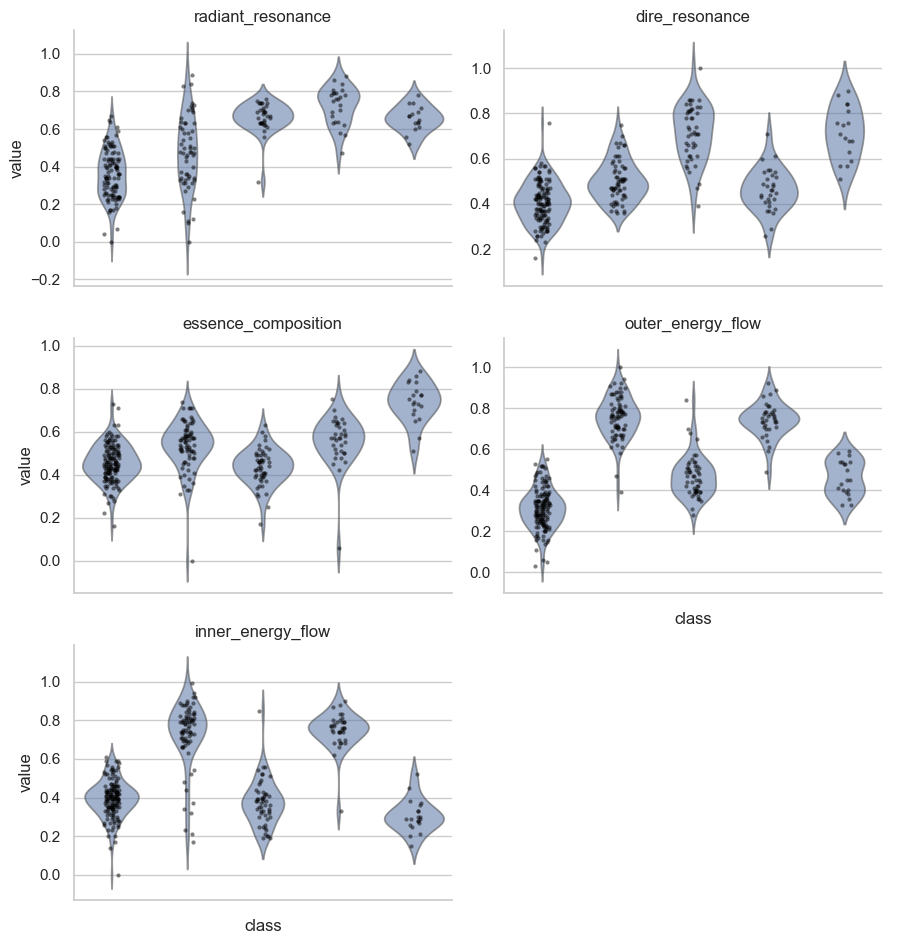

In [375]:
melted = df_plot.melt(id_vars='class', value_vars=num_cols,
                      var_name='feature', value_name='value')

g = sns.catplot(data=melted, x='class', y='value', col='feature', col_wrap=2,
                kind='violin', height=3.2, aspect=1.4, sharey=False,
                order=reliable, inner=None, alpha=0.55)
g.map_dataframe(sns.stripplot, x='class', y='value', color='black',
                s=3, alpha=0.5, jitter=True)
g.set_xticklabels(rotation=30, ha='right')
g.set_titles('{col_name}')
plt.tight_layout()
plt.show()

### 8.2.1. Выводы по violin plot (связь непрерывных признаков с классом)

**`radiant_resonance` — сильный нелинейный разделитель.** Медиана монотонно растёт от `inner_core` (~0.36) к `deep_barrier` (~0.76). Двумодальность, найденная в 5.2 на полной выборке, оказывается смесью классов: левый горб = `inner_core`, правый = `deep_barrier`/`outer_layer`. Линейные модели по этому признаку слабы, деревья/бустинг — сильны.

**`dire_resonance` — умеренный разделитель.** Расхождения медиан есть (~0.41 … 0.72), но немонотонно (`deep_barrier` проваливается ниже `inner_layer`). Разделяет слабее `radiant`, но не плоский.

**`essence_composition` — маркер узкого подмножества.** Первые три класса почти неотличимы (~0.44–0.55); резко выделяется только `outer_layer` (~0.75). Согласуется с изолированностью в корреляциях (max r=0.28): сигнал есть, но направленный на один класс.

**`outer_energy_flow` / `inner_energy_flow` — сильные дублирующие носители.** Оба резко отделяют `inner_core` (низкие значения ~0.31/0.40) от остальных четырёх классов (высокие ~0.46–0.78). Паттерны похожи → визуальное подтверждение r=0.81 из блока 8.1. Пара несёт один и тот же сигнал о локации энергии.

**Сводка:** все пять непрерывных признаков несут сигнал разного типа. Ни один не оказался полностью плоским. Порядок силы разделения: `radiant` ≈ `outer`/`inner` > `dire` > `essence`.

In [376]:
med = df.groupby('class')[num_cols].median().round(3)
med.insert(0, 'n', df['class'].value_counts())
med.sort_values('n', ascending=False)

,n,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow
class,,,,,,
inner_core,143,0.360,0.410,0.450,0.310,0.400
inner_barrier,77,0.480,0.495,0.550,0.760,0.780
inner_layer,52,0.670,0.715,0.440,0.460,0.375
deep_barrier,35,0.760,0.460,0.570,0.750,0.760
outer_layer,20,0.660,0.710,0.745,0.450,0.290
outer_crust,5,0.680,0.520,0.540,0.560,0.280
inner_crust,2,0.725,0.470,0.455,0.645,0.570
penetration_layer,2,0.740,0.510,0.535,0.640,0.570


<a id='sec10'></a>
## 10. Приведение типов

**Обоснование.** На этапе EDA мы выявили два дефекта природы признаков:
- `energy_charge` — вырожденный индикатор (уровень `1.00` представлен **одним** наблюдением из 336);
- `arcane_mark` — двухуровневое событие (база `0.48` / редкое `1.00`), как float в модель не идёт.

Оба требуют действий **до** разделения на train/test, потому что это детерминированные семантические правила, а не статистические оценки по выборке. Это принципиальное отличие от заполнения пропусков резонансов (KNN/mean/mode), которое ждёт сплита ради предотвращения горизонтальной утечки (блок 9).

### Что делаем и почему это безопасно

| Действие | Тип операции  | Обоснование |
|----------|--------------|-------------|
| Удалить `energy_charge` | Семантическое | Вырождение — факт постановки задачи, не зависит от состава train/test |
| Перекодировать `arcane_mark` → бинарный флаг `(value == 1.00)` | Детерминированное правило | Константа из легенды Invoker; параметр не вычисляется по данным |
| Понижение `float64 → float32` для непрерывных | Форматирование типа | eps(float32)≈1e-7 << шаг сетки данных 0.01; двумодальность и корреляции сохраняются |
| Понижение `int64 → int8` для флага | Форматирование типа | Целочисленный признак 0/1, потеря нулевая |

**Побочный эффект перекодирования `arcane_mark`:** 24 пропуска столбца автоматически кодируются нулём флага (`NaN == 1.00 → False → 0`), что семантически верно («метка не зафиксирована» = «метки нет»). Отдельный fillna для этого столбца больше не нужен — источник потерь закрыт бесплатно. После этого пропуски остаются только в двух непрерывных резонансах.

**Target `class` не трогаем:** sklearn-классификаторы принимают строковые метки сами (label-encoding происходит внутри `.fit()`), поэтому ручная конвертация target в числа здесь избыточна и относится к формату выхода модели, а не к предобработке признаков.

In [377]:
if 'energy_charge' in df.columns:
    df = df.drop(columns=['energy_charge'])

df['arcane_mark'] = (df['arcane_mark'] == 1.00).astype("int8")


In [378]:
num_cols  = [
    'radiant_resonance', 'dire_resonance', 'essence_composition',
    'outer_energy_flow', 'inner_energy_flow',
]
flag_cols = ['arcane_mark']
miss_cols = ['radiant_resonance', 'dire_resonance']

In [379]:
df[num_cols] = df[num_cols].astype('float32')

In [380]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float32
 1   dire_resonance       289 non-null    float32
 2   arcane_mark          336 non-null    int8   
 3   essence_composition  336 non-null    float32
 4   outer_energy_flow    336 non-null    float32
 5   inner_energy_flow    336 non-null    float32
 6   class                336 non-null    str    
dtypes: float32(5), int8(1), str(1)
memory usage: 9.6 KB


<a id='sec11'></a>
## 11. Разделение на train/test и применение заполнения пропусков

На этом этапе выполняем две операции, которые были отложены из EDA ради предотвращения горизонтальной утечки (блок 10):

1. **Стратифицированный сплит** по `class` (доля test = 0.20, чтобы гарантировать попадание сверхредких классов в обе части).
2. **Применение зафиксированного правила заполнения** (`KNNImputer`) к train и перенос на test через `transform` без повторного `fit`.

Это ровно тот механизм, который обсуждался в блоке 10: параметр считается по train, переносится на test как фиксированное преобразование → утечка исключена.

### 11.1. Стратегия разделения выборки

**Проблема.** При n=336 и трёх классах по 2–5 наблюдений (`outer_crust`=5, `penetration_layer`=2, `inner_crust`=2) стандартный `test_size=0.15` даёт ~50 строк в test, и сверхредкие классы могут оказаться полностью или частично только в одной части → sklearn выдаст warning или ошибку стратификации.

**Решение.** Увеличиваем долю test до **0.20**, чтобы каждый класс гарантированно попал в обе части (при 2 наблюдениях минимальный split = 1+1). Альтернатива — агрегация редких классов перед сплитом, но это изменяет постановку задачи (теряем различие между `outer_crust` / `penetration_layer` / `inner_crust`), поэтому оставляем все 8 классов как есть и компенсируем малый объём увеличением test-доли.

**Seed.** Фиксируем `random_state=SEED` (=5) для воспроизводимости всего пайплайна.

In [381]:
TEST_SIZE = 0.30

train_df, test_df = train_test_split(
    df,
    stratify=df['class'],
    test_size=TEST_SIZE,
    random_state=SEED,
    shuffle=True
)

print(f'train: {train_df.shape}, test: {test_df.shape}')
print('\nБаланс классов в train:')
print(train_df['class'].value_counts().sort_index())
print('\nБаланс классов в test:')
print(test_df['class'].value_counts().sort_index())

train: (235, 7), test: (101, 7)

Баланс классов в train:
class
deep_barrier          25
inner_barrier         54
inner_core           100
inner_crust            1
inner_layer           36
outer_crust            4
outer_layer           14
penetration_layer      1
Name: count, dtype: int64

Баланс классов в test:
class
deep_barrier         10
inner_barrier        23
inner_core           43
inner_crust           1
inner_layer          16
outer_crust           1
outer_layer           6
penetration_layer     1
Name: count, dtype: int64


### 11.2. Проверка покрытия: признаки с пропусками в test ⊆ признаки с пропусками в train

In [382]:
miss_cols_current = ['radiant_resonance', 'dire_resonance']

nan_train = train_df[miss_cols_current].isna().sum()
nan_test = test_df[miss_cols_current].isna().sum()

coverage_check = np.isin(nan_test[nan_test > 0].index, nan_train[nan_train > 0].index)

print('Пропуски в train:', nan_train.to_dict())
print('Пропуски в test :', nan_test.to_dict())
print('Покрытие (test ⊆ train):', coverage_check.all())

Пропуски в train: {'radiant_resonance': 62, 'dire_resonance': 30}
Пропуски в test : {'radiant_resonance': 26, 'dire_resonance': 17}
Покрытие (test ⊆ train): True


### 11.3. Заполнение пропусков: KNNImputer на train

Согласно блоку 8, машинный метод (`knn`) выбран как основной для непрерывных резонансов из-за асимметрии риска: он кратно выигрывает там, где есть корреляционная опора (`outer`↔`inner`, r=0.81), и нигде значимо не проигрывает статистике. Параметр `n_neighbors=5` взят как стартовое значение (будет подобран позже на этапе обучения модели через cross-validation).

In [383]:
IMPUTER_PARAMS = {'n_neighbors': 5}

imputer = KNNImputer(**IMPUTER_PARAMS)

X_train_raw = train_df[num_cols]
X_train_filled = imputer.fit_transform(X_train_raw)

X_test_raw = test_df[num_cols]
X_test_filled = imputer.transform(X_test_raw)

X_train_filled = pd.DataFrame(X_train_filled, columns=num_cols, index=train_df.index)
X_test_filled = pd.DataFrame(X_test_filled, columns=num_cols, index=test_df.index)

print('Train после заполнения:')
print(X_train_filled.isna().sum().to_dict())
print('\nTest после заполнения:')
print(X_test_filled.isna().sum().to_dict())

Train после заполнения:
{'radiant_resonance': 0, 'dire_resonance': 0, 'essence_composition': 0, 'outer_energy_flow': 0, 'inner_energy_flow': 0}

Test после заполнения:
{'radiant_resonance': 0, 'dire_resonance': 0, 'essence_composition': 0, 'outer_energy_flow': 0, 'inner_energy_flow': 0}


### 11.4. Сборка предобработанных выборок

**Состав итоговых таблиц:**
- Признаковая часть X: 5 непрерывных (заполненные KNN) + 1 бинарный флаг `arcane_mark_flag` (пропуски устранены перекодированием в блоке 10).
- Целевая часть y: `class` остаётся строковым (sklearn закодирует внутри `.fit()`).

**Формат хранения.** Разделяем X и y сразу, чтобы дальше работать с ними независимо (например, при подборе гиперпараметров или ансамблировании).

In [384]:
flag_cols = ['arcane_mark']

X_train = pd.concat([X_train_filled, train_df[flag_cols]], axis=1)
y_train = train_df['class']

X_test = pd.concat([X_test_filled, test_df[flag_cols]], axis=1)
y_test = test_df['class']

print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape :', X_test.shape)
print('y_test shape :', y_test.shape)

print('\nТипы данных X_train:')
X_train.dtypes

print('\nПервые 3 строки X_train:')
X_train.head(3)

X_train shape: (235, 6)
y_train shape: (235,)
X_test shape : (101, 6)
y_test shape : (101,)

Типы данных X_train:

Первые 3 строки X_train:


,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow,arcane_mark
24,0.332,0.39,0.48,0.22,0.23,0
171,0.576,0.44,0.55,0.88,0.89,0
113,0.380,0.30,0.43,0.29,0.39,0


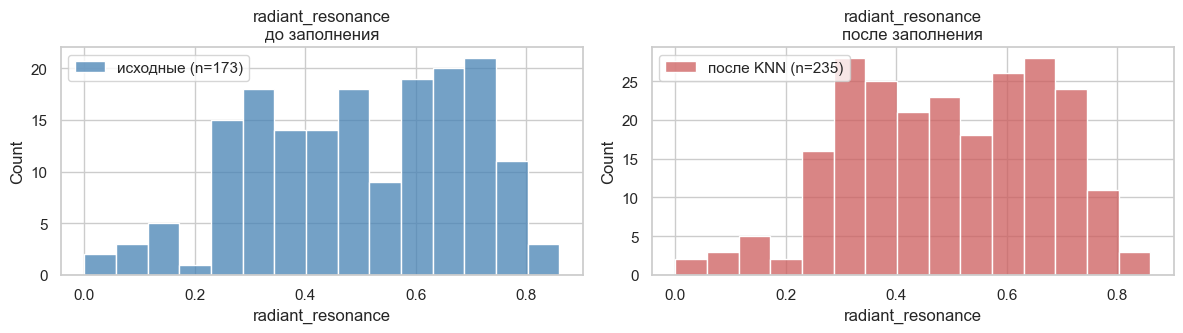

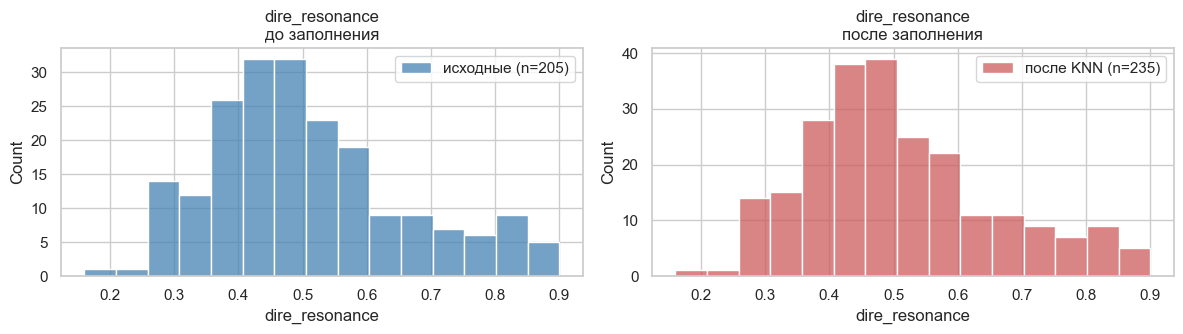

In [385]:
def check_imputation_quality(original_series, filled_array, col_name, bins=15):
    """Сравнение распределения до (dropna) и после заполнения."""
    x_orig = original_series.dropna()
    x_filled = pd.Series(filled_array).dropna()
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    
    lo, hi = x_orig.min(), x_orig.max()
    edges = np.linspace(lo, hi, bins + 1)
    
    sns.histplot(x_orig, bins=edges, ax=axes[0], color='steelblue', label=f'исходные (n={len(x_orig)})')
    axes[0].set_title(f'{col_name}\nдо заполнения')
    axes[0].legend()
    
    sns.histplot(x_filled, bins=edges, ax=axes[1], color='indianred', label=f'после KNN (n={len(x_filled)})')
    axes[1].set_title(f'{col_name}\nпосле заполнения')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

for col in miss_cols_current:
    check_imputation_quality(
        train_df[col],
        X_train_filled[col],
        col
    )

### 11.5.1. Анализ искажений при машинном заполнении

**Наблюдения.** При визуальном сравнении распределений до и после заполнения KNN наблюдаются следующие эффекты:

1.  **Заполнение «провала» плотности.** В исходных данных `radiant_resonance` имелся выраженный минимум плотности в диапазоне ~0.45–0.55 (между двумя модами). После применения KNN этот провал частично заполнился новыми значениями.
2.  **Сглаживание бимодальности.** Два отчетливых горба стали менее выраженными, слившись в более широкое плато. Это следствие того, что KNN усредняет признаки соседей: объекты, находящиеся «на границе» между кластерами, получают значения, лежащие посередине.
3.  **Отсутствие артефактных пиков.** В отличие от статистического заполнения (мода), здесь не возникло искусственного острого пика в одной точке (см. блок 8.1). Новые значения распределены диффузно.